In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df=pd.read_csv('housing.csv')
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41,880,129.0,322,126,8.3252,452600,NEAR BAY
1,-122.22,37.86,21,7099,1106.0,2401,1138,8.3014,358500,NEAR BAY
2,-122.24,37.85,52,1467,190.0,496,177,7.2574,352100,NEAR BAY
3,-122.25,37.85,52,1274,235.0,558,219,5.6431,341300,NEAR BAY
4,-122.25,37.85,52,1627,280.0,565,259,3.8462,342200,NEAR BAY


In [3]:
def compute_cost(x_train,y_train,w,b):
    
    m=len(x_train)
    f=np.dot(x_train,w)+b
    error=f-y_train
    cost=np.sum(error**2)/(2*m)

    return cost

In [4]:
def compute_gradient(x,y,w,b):

    m=len(x)
    f=np.dot(x,w)+b
    error=f-y
    dj_dw=np.dot(x.T,error)/m
    dj_db=np.sum(error)/m
    
    
    return dj_dw, dj_db

In [5]:
def gradient_descent(x,y,w,b,alpha,epoch):
    cost_history=[]

    for i in range(epoch):
        dj_dw,dj_db=compute_gradient(x,y,w,b)
        w=w-alpha*dj_dw
        b=b-alpha*dj_db
        cost=compute_cost(x,y,w,b)
        cost_history.append(cost)
    
    return w,b,cost_history


In [6]:
#dropping unnessesary columns and null values
df.drop(columns=['ocean_proximity'],inplace=True)
print(df.isnull().sum())
df['total_bedrooms'] = df['total_bedrooms'].fillna(df['total_bedrooms'].mean())
y_train=df['median_house_value']
x_train=df.drop(columns=['median_house_value'])

#using feature scaling
mean=np.mean(x_train,axis=0)
std=np.std(x_train,axis=0)
x_norm=(x_train-mean)/std


longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
dtype: int64


In [7]:
#taking x and y to numpy to for calculation
X=x_norm.to_numpy()
Y=y_train.to_numpy()

m,n=np.shape(X)
w=np.zeros(n)
b=0
alpha=0.01
epoch=2000
w,b,cost_history=gradient_descent(X,Y,w,b,alpha,epoch)

Y_pred=np.dot(X,w)+b


In [8]:
from sklearn.metrics import r2_score

r2 = r2_score(Y, Y_pred)
print("R2 Score:", r2)

R2 Score: 0.6306283922628109


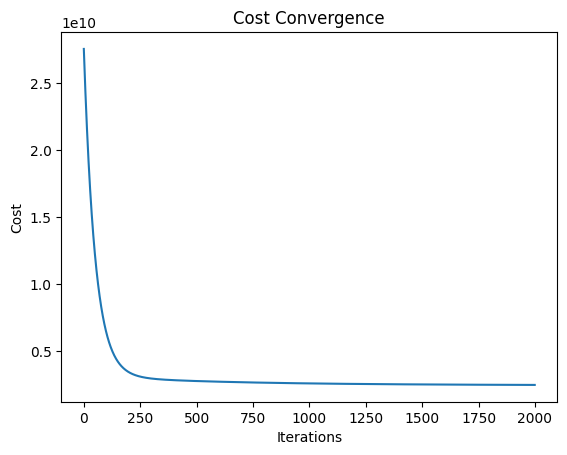

In [9]:
plt.plot(cost_history)
plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Cost Convergence")
plt.show()